# LEGO Inventory – Person 1: Preprocessing and Segmentation

This notebook covers image loading, preprocessing and segmentation of LEGO brick photographs.

## 1. Imports

We import the libraries used in this notebook and print their versions, so the results can be reproduced later.

In [93]:
import random
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Record the library versions used for this run.
print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)

OpenCV: 5.0.0
NumPy: 2.5.3


## 2. Select a random test image

The test photographs are in the `test_images` folder. We find the image files, then pick one at random. Each time this cell runs, a different photo can be chosen.

In [94]:
TEST_IMAGE_DIR = Path("test_images")
IMAGE_EXTENSIONS = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}


def list_test_images(folder):
    """Return the image files in a folder, sorted by name."""
    files = [
        path for path in folder.iterdir()
        if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS
    ]
    # Sorting keeps the list in the same order on every run.
    return sorted(files)


image_files = list_test_images(TEST_IMAGE_DIR)

# Stop early with a clear message if the folder is empty or missing.
if not image_files:
    raise FileNotFoundError(f"No images found in {TEST_IMAGE_DIR.resolve()}")

# random.choice picks one file from the list.
selected_image_path = random.choice(image_files)

print(f"Found {len(image_files)} test image(s).")
print(f"Selected: {selected_image_path}")

Found 4 test image(s).
Selected: test_images\2_red_lego_pieces.png


## 3. Load and show the selected image

OpenCV loads images in BGR order, but Matplotlib expects RGB. We convert the colours before showing the photo, so the bricks look the right colour.

Image size (height, width, channels): (1080, 1920, 3)


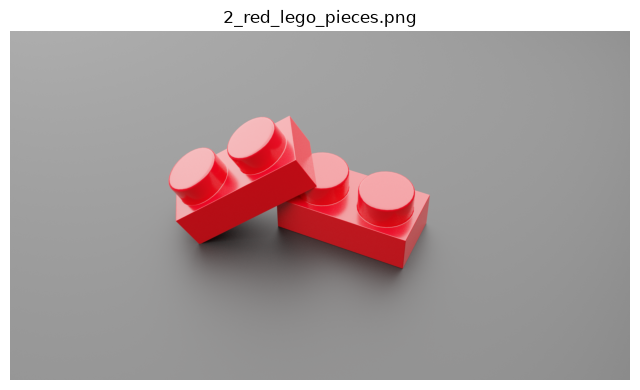

In [95]:
# IMREAD_COLOR returns 3 channels (BGR) and drops any transparency channel.
image_bgr = cv2.imread(str(selected_image_path), cv2.IMREAD_COLOR)

# imread returns None if the file cannot be read, so check for that.
if image_bgr is None:
    raise ValueError(f"Could not load image: {selected_image_path}")

image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)

print(f"Image size (height, width, channels): {image_rgb.shape}")

plt.figure(figsize=(8, 6))
plt.imshow(image_rgb)
plt.title(selected_image_path.name)
plt.axis("off")
plt.show()

## 4. Smoothing and Lab colour space

A light **Gaussian blur** smooths out stud texture and sensor noise. Without it, these small details create ragged edges in the mask.

We then convert the photo to the **CIELAB (Lab)** colour space. L is lightness, and a and b describe the colour. Lab was designed so that the straight-line distance between two colours roughly matches how different they look to a person (the CIE 1976 colour difference). Having lightness and colour in separate channels is important here: grey bricks differ from a white background only in **lightness**, while pale bricks (cream, light yellow) differ mainly in **colour**.

The background colour is the **median colour of the border pixels**, because the outer edge of the photo is almost always background.

Background colour (L, a, b): [159. 128. 128.]


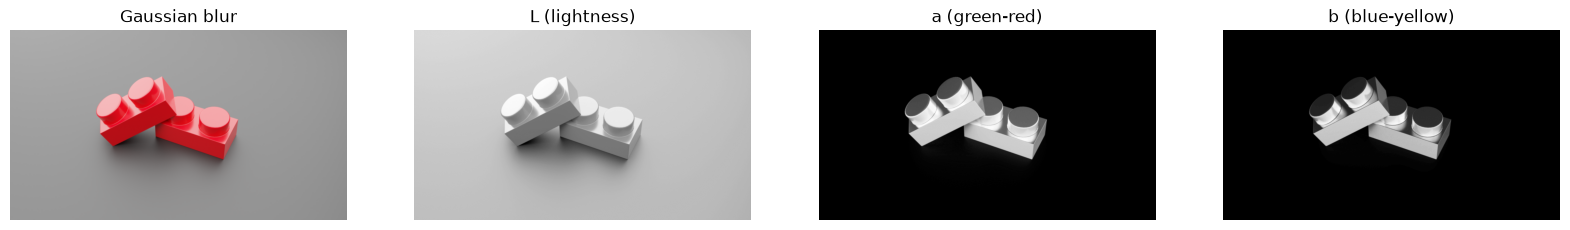

In [96]:
def get_border_pixels(image):
    # Pixels along the four edges of the image (works for 1 or 3 channels).
    return np.concatenate([image[0, :], image[-1, :], image[:, 0], image[:, -1]])


def lab_and_background(image_bgr):
    # --- Smoothing, then conversion to Lab ---
    # float32 lets us subtract colours without 8-bit values wrapping around.
    blurred = cv2.GaussianBlur(image_bgr, (5, 5), 0)
    lab = cv2.cvtColor(blurred, cv2.COLOR_BGR2LAB).astype(np.float32)

    # --- Background colour: median (L, a, b) of the border pixels ---
    background_lab = np.median(get_border_pixels(lab), axis=0)
    return blurred, lab, background_lab


image_blur, image_lab, background_lab = lab_and_background(image_bgr)
print(f"Background colour (L, a, b): {background_lab}")

fig, axes = plt.subplots(1, 4, figsize=(20, 4))
axes[0].imshow(cv2.cvtColor(image_blur, cv2.COLOR_BGR2RGB))
axes[0].set_title("Gaussian blur")
for i, name in enumerate(["L (lightness)", "a (green-red)", "b (blue-yellow)"], start=1):
    axes[i].imshow(image_lab[:, :, i - 1], cmap="gray")
    axes[i].set_title(name)
for ax in axes:
    ax.axis("off")
plt.show()

## 5. Binary mask from three simple cues

One threshold on one measurement is not enough for real photos: very colourful bricks push the threshold so high that pale and grey bricks are lost. So a pixel is marked as **brick** if **any** of these three cues is true:

1. **Colour distance** – its Lab distance from the background colour is above an Otsu threshold. This catches most bricks, especially strong colours.
2. **Colour only** – its distance in the colour channels (a, b) alone is above its own Otsu threshold. Lightness is ignored, so pale bricks such as cream and light yellow are caught even on a white background.
3. **Much darker** – its lightness is below 75% of the background lightness. This catches grey and black bricks, which have almost no colour.

**Otsu's method** picks each threshold automatically from the histogram, so nothing needs tuning per photo except the 75% darkness ratio.

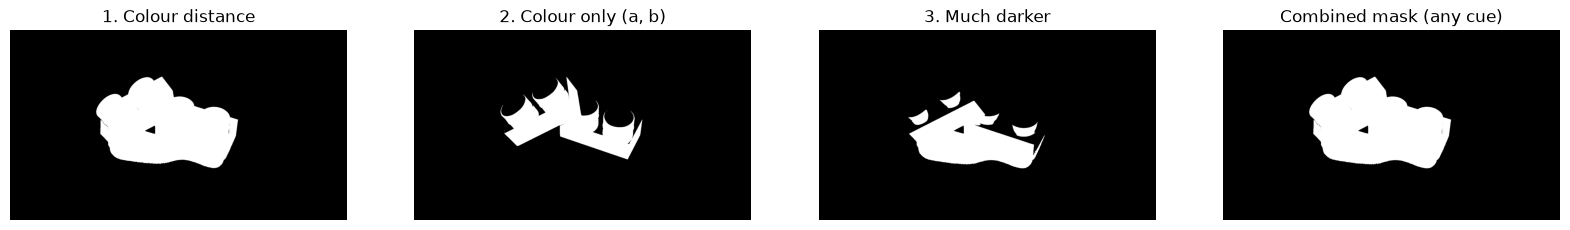

In [97]:
DARK_RATIO = 0.75  # "much darker" = below 75% of the background lightness


def otsu_mask(values):
    # Otsu threshold on any measurement (clipped to 0-255 so it fits in 8 bits).
    values_8bit = np.clip(values, 0, 255).astype(np.uint8)
    threshold, _ = cv2.threshold(values_8bit, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    return values > threshold


def brick_cues(lab, background_lab):
    # --- Cue 1: full Lab distance from the background colour ---
    colour_distance = np.sqrt(np.sum((lab - background_lab) ** 2, axis=2))
    by_colour_distance = otsu_mask(colour_distance)

    # --- Cue 2: distance in the colour channels (a, b) only ---
    colour_only = np.sqrt(np.sum((lab[:, :, 1:] - background_lab[1:]) ** 2, axis=2))
    by_colour_only = otsu_mask(colour_only)

    # --- Cue 3: much darker than the background ---
    by_darkness = lab[:, :, 0] < DARK_RATIO * background_lab[0]

    return by_colour_distance, by_colour_only, by_darkness


cue_distance, cue_colour, cue_dark = brick_cues(image_lab, background_lab)

# A pixel is a brick if any cue says so.
mask_cues = ((cue_distance | cue_colour | cue_dark) * 255).astype(np.uint8)

fig, axes = plt.subplots(1, 4, figsize=(20, 4))
panels = [(cue_distance, "1. Colour distance"), (cue_colour, "2. Colour only (a, b)"),
          (cue_dark, "3. Much darker"), (mask_cues, "Combined mask (any cue)")]
for ax, (mask, title) in zip(axes, panels):
    ax.imshow(mask, cmap="gray")
    ax.set_title(title)
    ax.axis("off")
plt.show()

## 6. Remove shadows

Shadows can pass the "much darker" cue. But a shadow differs from a grey brick in two ways:

1. A shadow keeps the background's **colour** (it only gets darker).
2. A shadow is **smooth**, while a brick has studs and sharp edges. We measure smoothness with the **local standard deviation** of lightness: how much the lightness varies inside a small window around each pixel (about 1% of the image size). Smooth areas have a low value.

A pixel is treated as shadow if it is darker than the background, keeps the background colour, **and** is smooth. Shadow pixels are removed from the mask.

**Limitation:** a large, flat, grey surface with no studs visible (for example the side of a big grey brick) can look like a shadow. If grey bricks lose parts, set `remove_shadows=False` in the final function (section 10).

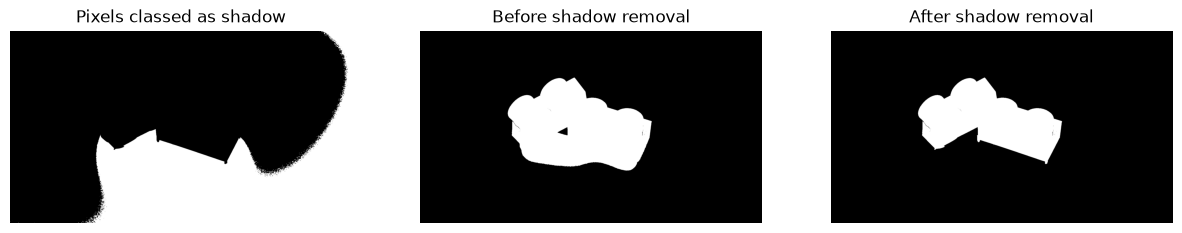

In [98]:
SHADOW_MAX_COLOUR_CHANGE = 10  # shadows keep the background colour
SHADOW_MAX_TEXTURE = 15        # shadows are smooth (low local standard deviation)


def local_standard_deviation(values, window):
    # std = sqrt(mean of squares - square of mean), each mean taken over the window.
    mean = cv2.blur(values, (window, window))
    mean_of_squares = cv2.blur(values * values, (window, window))
    return np.sqrt(np.maximum(mean_of_squares - mean * mean, 0))


def find_shadow_pixels(lab, background_lab):
    lightness = lab[:, :, 0]

    # --- Colour change, using a and b only ---
    colour_change = np.sqrt(np.sum((lab[:, :, 1:] - background_lab[1:]) ** 2, axis=2))

    # --- Texture: window about 1% of the image size (odd, at least 3) ---
    window = max(3, int(0.01 * max(lab.shape[:2])) | 1)
    texture = local_standard_deviation(lightness, window)

    darker = lightness < background_lab[0]
    same_colour = colour_change < SHADOW_MAX_COLOUR_CHANGE
    smooth = texture < SHADOW_MAX_TEXTURE
    return darker & same_colour & smooth


# --- Find shadow pixels and remove them from the mask ---
shadow = find_shadow_pixels(image_lab, background_lab)
mask_no_shadow = mask_cues.copy()
mask_no_shadow[shadow] = 0

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(shadow, cmap="gray")
axes[0].set_title("Pixels classed as shadow")
axes[1].imshow(mask_cues, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Before shadow removal")
axes[2].imshow(mask_no_shadow, cmap="gray", vmin=0, vmax=255)
axes[2].set_title("After shadow removal")
for ax in axes:
    ax.axis("off")
plt.show()

## 7. Clean up the mask

Three small steps tidy the mask:

1. **Opening** (erosion then dilation) removes small specks of noise, such as the leftover watermark dots in `3_red_lego_pieces.png`. **Closing** (dilation then erosion) fills small gaps inside the bricks. An ellipse kernel suits the rounded corners of bricks.
   - The opening kernel is **9×9**: any speck narrower than 9 pixels disappears, while the smallest test brick (about 20 pixels wide) survives.
   - The closing kernel stays **5×5**. A larger closing can bridge the narrow gap between touching bricks, which makes them harder to separate in section 9.
2. **Remove objects touching the image border.** This removes the "dreamstime.com" watermark banner in `3_red_lego_pieces.png`. A brick cut off by the photo edge is also removed, which is usually what you want for an inventory. It can be switched off with `remove_border=False`.
3. **Fill holes** inside bricks with a flood fill from the corner: anything the flood cannot reach from outside is a hole.

No objects are filtered by size here. Filtering false detections by area is Person 2's stage.

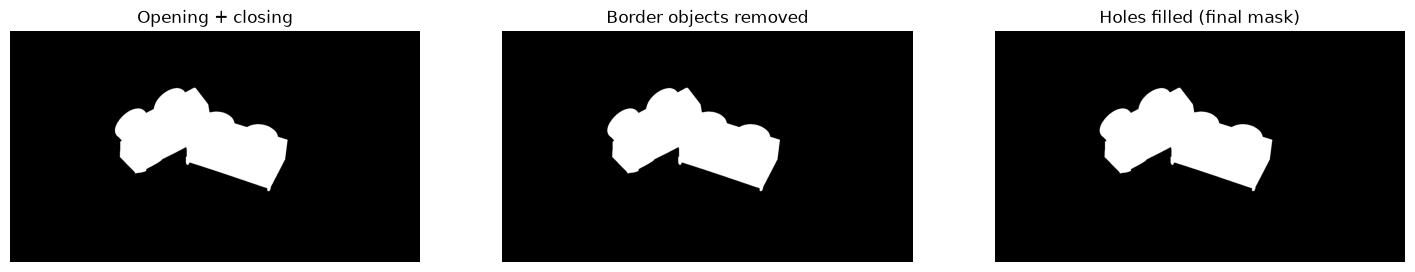

In [99]:
# Opening removes specks narrower than 9 px; closing fills gaps up to 5 px.
opening_kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (9, 9))
closing_kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))


def open_and_close(mask):
    # --- Morphology: opening removes specks, closing fills small gaps ---
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, opening_kernel)
    return cv2.morphologyEx(mask, cv2.MORPH_CLOSE, closing_kernel)


def remove_border_objects(mask):
    # --- Clear border: delete every white region that touches the image edge ---
    _, labels = cv2.connectedComponents(mask, connectivity=8)
    cleaned = mask.copy()
    for label in np.unique(get_border_pixels(labels)):
        if label != 0:  # 0 is the background
            cleaned[labels == label] = 0
    return cleaned


def fill_holes(mask):
    # --- Hole filling with a flood fill from the corner ---
    # A 1-pixel black frame lets the flood go round the outside, even if a
    # brick touches an edge. floodFill needs a mask 2 px larger than the image.
    padded = cv2.copyMakeBorder(mask, 1, 1, 1, 1, cv2.BORDER_CONSTANT, value=0)
    flooded = padded.copy()
    flood_mask = np.zeros((padded.shape[0] + 2, padded.shape[1] + 2), np.uint8)
    cv2.floodFill(flooded, flood_mask, (0, 0), 255)

    # Pixels the flood could not reach are holes inside bricks.
    holes = cv2.bitwise_not(flooded)[1:-1, 1:-1]
    return cv2.bitwise_or(mask, holes)


# --- Apply the clean-up steps in order ---
mask_opened_closed = open_and_close(mask_no_shadow)
mask_no_border = remove_border_objects(mask_opened_closed)
mask_clean = fill_holes(mask_no_border)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
steps = [(mask_opened_closed, "Opening + closing"),
         (mask_no_border, "Border objects removed"),
         (mask_clean, "Holes filled (final mask)")]
for ax, (mask, title) in zip(axes, steps):
    ax.imshow(mask, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")
plt.show()

## 8. Check against the alpha reference mask

Some test images have a transparency (alpha) channel that marks exactly where the bricks are. If it has transparent pixels, we use it to score our mask with **Intersection over Union (IoU)**: the overlap of the two masks divided by their combined area. 1.0 is a perfect match.

Images with a fully opaque alpha channel (all 255) give no reference, so the check is skipped for them.

In [100]:
def intersection_over_union(mask_a, mask_b):
    a = mask_a > 0
    b = mask_b > 0
    return (a & b).sum() / (a | b).sum()


# --- Read the file again with IMREAD_UNCHANGED so the alpha channel is kept ---
image_raw = cv2.imread(str(selected_image_path), cv2.IMREAD_UNCHANGED)
has_alpha = image_raw.ndim == 3 and image_raw.shape[2] == 4
has_useful_alpha = has_alpha and np.any(image_raw[:, :, 3] < 255)

if has_useful_alpha:
    _, mask_alpha = cv2.threshold(image_raw[:, :, 3], 127, 255, cv2.THRESH_BINARY)
    print(f"IoU with the alpha reference mask: {intersection_over_union(mask_clean, mask_alpha):.3f}")

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    axes[0].imshow(mask_alpha, cmap="gray", vmin=0, vmax=255)
    axes[0].set_title("Alpha reference mask")
    axes[1].imshow(mask_clean, cmap="gray", vmin=0, vmax=255)
    axes[1].set_title("Our final mask")
    for ax in axes:
        ax.axis("off")
    plt.show()
else:
    print("No useful alpha channel in this image, so there is no reference mask.")

No useful alpha channel in this image, so there is no reference mask.


## 9. Separate touching bricks

Touching bricks form one white region. We give the watershed **one seed per brick** and let it grow the seeds to fill the region.

**Normal regions – distance transform.** Each white pixel gets its distance to the nearest black pixel. The deepest pixels (above 80% of the region's maximum) become the seed. This works when touching bricks form a shape with narrow joins.

**Unusually large regions – cut along straight edges.** Tightly packed groups of same-colour bricks form a solid block with no narrow joins, so one seed would cover the whole group. But the joins between bricks are **long straight edges**, while studs only make short curved edges. So for a region much larger than a typical region (more than 1.5 × the median region area):

1. **Canny edge detection** finds edge pixels inside the region.
2. The **probabilistic Hough transform** (`cv2.HoughLinesP`) keeps only long straight line segments (at least 2.5% of the image size), so stud outlines are ignored.
3. The lines are drawn into the region as thin black cuts, splitting it into pieces.
4. Each piece that is deep enough (at least 0.8% of the image size from its edge) gets a seed. Thin slivers, such as the side face of a brick, get no seed and are later absorbed by a neighbour.

**Marker-controlled watershed.** The watershed floods the photo from the seeds. Where floods from two seeds meet, it draws a boundary. OpenCV's version follows colour changes in the photo, so boundaries tend to land on real brick edges.

The result is a **label image**: `0` = background and `1, 2, 3 …` = one brick region each.

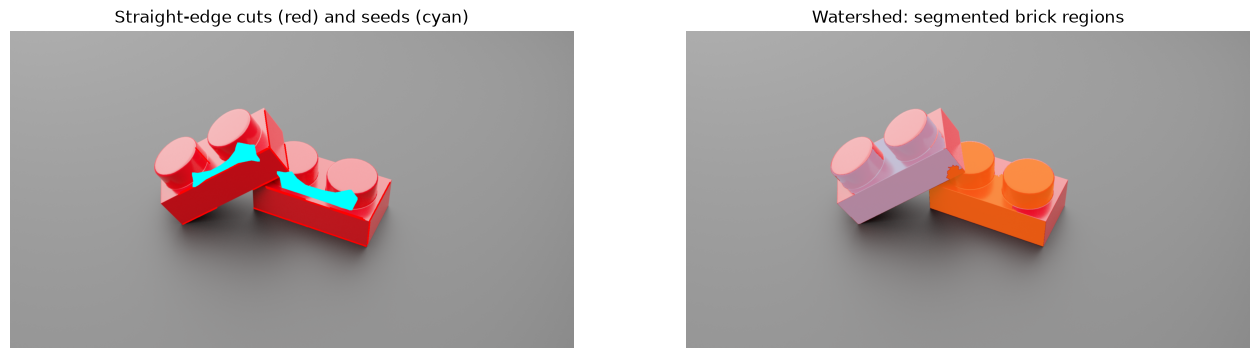

In [101]:
LARGE_REGION_FACTOR = 1.5    # "unusually large" = bigger than 1.5 x the median region
MIN_LINE_FRACTION = 0.025    # straight edges must be at least 2.5% of the image size
MIN_PIECE_DEPTH = 0.008      # pieces must be at least 0.8% of the image size deep


def find_straight_edges(image_bgr, mask):
    # --- Canny edges inside the bricks (outline edges are not needed) ---
    gray = cv2.GaussianBlur(cv2.cvtColor(image_bgr, cv2.COLOR_BGR2GRAY), (5, 5), 0)
    edges = cv2.Canny(gray, 15, 45)
    inside = cv2.erode(mask, np.ones((7, 7), np.uint8))
    edges[inside == 0] = 0

    # --- Keep only long straight segments (probabilistic Hough transform) ---
    size = max(image_bgr.shape[:2])
    min_length = int(MIN_LINE_FRACTION * size)
    lines = cv2.HoughLinesP(edges, 1, np.pi / 180, threshold=int(0.6 * min_length),
                            minLineLength=min_length, maxLineGap=5)

    # --- Draw the segments as 3-pixel-wide cut lines ---
    cut_lines = np.zeros_like(mask)
    if lines is not None:
        for x1, y1, x2, y2 in lines.reshape(-1, 4):
            cv2.line(cut_lines, (int(x1), int(y1)), (int(x2), int(y2)), 255, 3)
    return cut_lines


def seeds_from_pieces(in_region, cut_lines, min_depth):
    # --- Cut the region along the lines, then give each deep piece a seed ---
    pieces = (in_region & (cut_lines == 0)).astype(np.uint8) * 255
    piece_distance = cv2.distanceTransform(pieces, cv2.DIST_L2, 5)
    _, piece_labels = cv2.connectedComponents(pieces, connectivity=8)

    seeds = np.zeros(in_region.shape, dtype=bool)
    for piece in range(1, piece_labels.max() + 1):
        in_piece = piece_labels == piece
        depth = piece_distance[in_piece].max()
        if depth >= min_depth:  # thin slivers get no seed
            seeds |= in_piece & (piece_distance > 0.6 * depth)
    return seeds


def find_seeds(image_bgr, mask):
    # --- Measure each white region and the typical region size ---
    count, region_labels, stats, _ = cv2.connectedComponentsWithStats(mask, connectivity=8)
    areas = stats[1:, cv2.CC_STAT_AREA]
    typical_area = np.median(areas) if len(areas) > 0 else 0

    cut_lines = find_straight_edges(image_bgr, mask)
    distance_map = cv2.distanceTransform(mask, cv2.DIST_L2, 5)
    min_depth = MIN_PIECE_DEPTH * max(mask.shape)

    seeds = np.zeros_like(mask)
    for region in range(1, count):
        in_region = region_labels == region
        region_seeds = None

        # --- Large region: probably a packed group, so cut along straight edges ---
        if areas[region - 1] > LARGE_REGION_FACTOR * typical_area:
            region_seeds = seeds_from_pieces(in_region, cut_lines, min_depth)

        # --- Normal region (or no usable piece): deepest 20% of the distance map ---
        if region_seeds is None or not region_seeds.any():
            region_max = distance_map[in_region].max()
            region_seeds = in_region & (distance_map > 0.8 * region_max)

        seeds[region_seeds] = 255
    return seeds, cut_lines


def watershed_labels(image_bgr, mask, seeds):
    # --- Build the markers: 1 = background, 2, 3, ... = one seed each, 0 = unknown ---
    _, seed_labels = cv2.connectedComponents(seeds, connectivity=8)
    markers = seed_labels + 1
    markers[(mask > 0) & (seeds == 0)] = 0

    # --- Flood from the seeds; boundaries are marked with -1 ---
    markers = cv2.watershed(image_bgr, markers.astype(np.int32))

    # --- Convert to 0 = background, 1..N = brick regions ---
    # Boundary pixels (-1) become background, leaving a thin gap between
    # touching bricks so each region stays separate.
    labels = np.where(markers > 1, markers - 1, 0).astype(np.int32)
    labels[mask == 0] = 0
    return labels


def colour_labels(image_bgr, labels):
    # --- Visualisation: paint each region a different colour on the photo ---
    palette = plt.get_cmap("tab20")
    output = image_bgr.copy()
    for label in range(1, labels.max() + 1):
        bgr = (np.array(palette(label % 20)[:3]) * 255)[::-1]
        region = labels == label
        output[region] = (0.35 * output[region] + 0.65 * bgr).astype(np.uint8)
    return output


# --- Run the separation on the selected image ---
seeds, cut_lines = find_seeds(image_bgr, mask_clean)
brick_labels = watershed_labels(image_bgr, mask_clean, seeds)

# Show the cut lines in red and the seeds in cyan (thickened only for display).
seed_view = image_rgb.copy()
seed_view[cut_lines > 0] = (255, 0, 0)
seed_view[cv2.dilate(seeds, np.ones((9, 9), np.uint8)) > 0] = (0, 255, 255)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
axes[0].imshow(seed_view)
axes[0].set_title("Straight-edge cuts (red) and seeds (cyan)")
axes[1].imshow(cv2.cvtColor(colour_labels(image_bgr, brick_labels), cv2.COLOR_BGR2RGB))
axes[1].set_title("Watershed: segmented brick regions")
for ax in axes:
    ax.axis("off")
plt.show()

## 10. Final segmentation function

All the Person 1 steps above in one function, so Persons 2 and 3 can call it on any photo. It returns a dictionary:

| Key | Type | Meaning |
|---|---|---|
| `"preprocessed"` | BGR image | Gaussian-blurred photo |
| `"mask"` | 8-bit binary | Final foreground mask, bricks = 255 |
| `"seeds"` | 8-bit binary | Watershed seeds |
| `"labels"` | int32 image | **0 = background, 1..N = one brick region each** |
| `"brick_masks"` | list of 8-bit binary | One full-size mask per region (255 = that region) |

In [102]:
def segment_lego_image(image_bgr, remove_shadows=True, remove_border=True):
    # --- 1. Preprocessing: blur, Lab, background colour ---
    preprocessed, lab, background_lab = lab_and_background(image_bgr)

    # --- 2. Binary mask: any of the three cues ---
    by_distance, by_colour, by_darkness = brick_cues(lab, background_lab)
    mask = ((by_distance | by_colour | by_darkness) * 255).astype(np.uint8)

    # --- 3. Remove shadows, then clean up the mask ---
    if remove_shadows:
        mask[find_shadow_pixels(lab, background_lab)] = 0
    mask = open_and_close(mask)
    if remove_border:
        mask = remove_border_objects(mask)
    mask = fill_holes(mask)

    # --- 4. Separate touching bricks: seeds + watershed ---
    seeds, _ = find_seeds(image_bgr, mask)
    labels = watershed_labels(image_bgr, mask, seeds)

    # --- 5. One full-size mask per region for the next stages ---
    brick_masks = [np.where(labels == label, 255, 0).astype(np.uint8)
                   for label in range(1, labels.max() + 1)]

    return {"preprocessed": preprocessed, "mask": mask, "seeds": seeds,
            "labels": labels, "brick_masks": brick_masks}

### Run on every test photo (for testing purposes only)

For each photo we show the expected outputs for Person 1: original image, preprocessed image, binary segmentation mask and segmented brick regions.

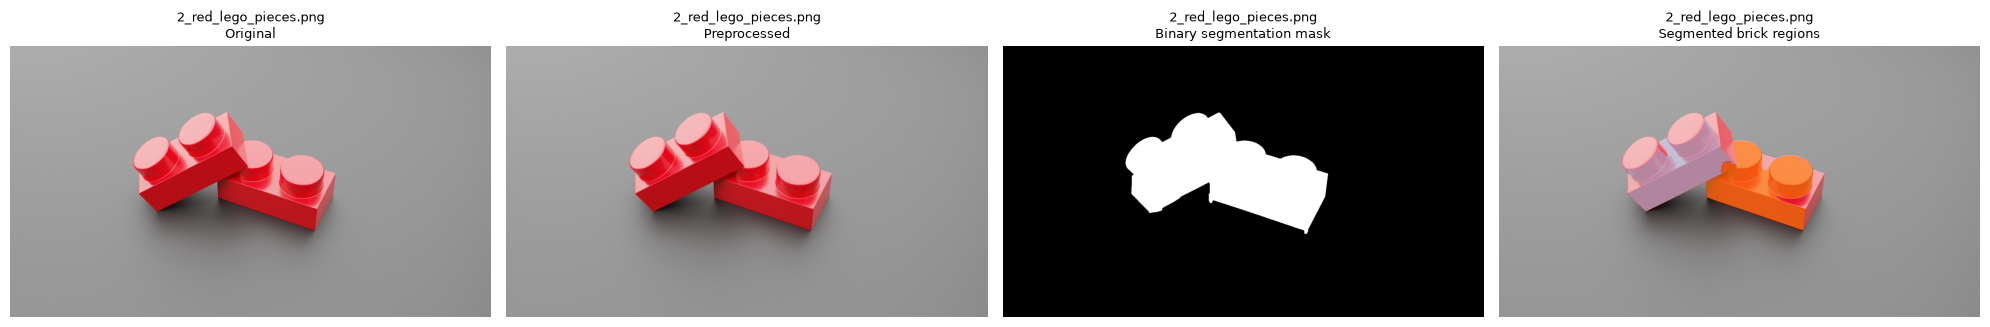

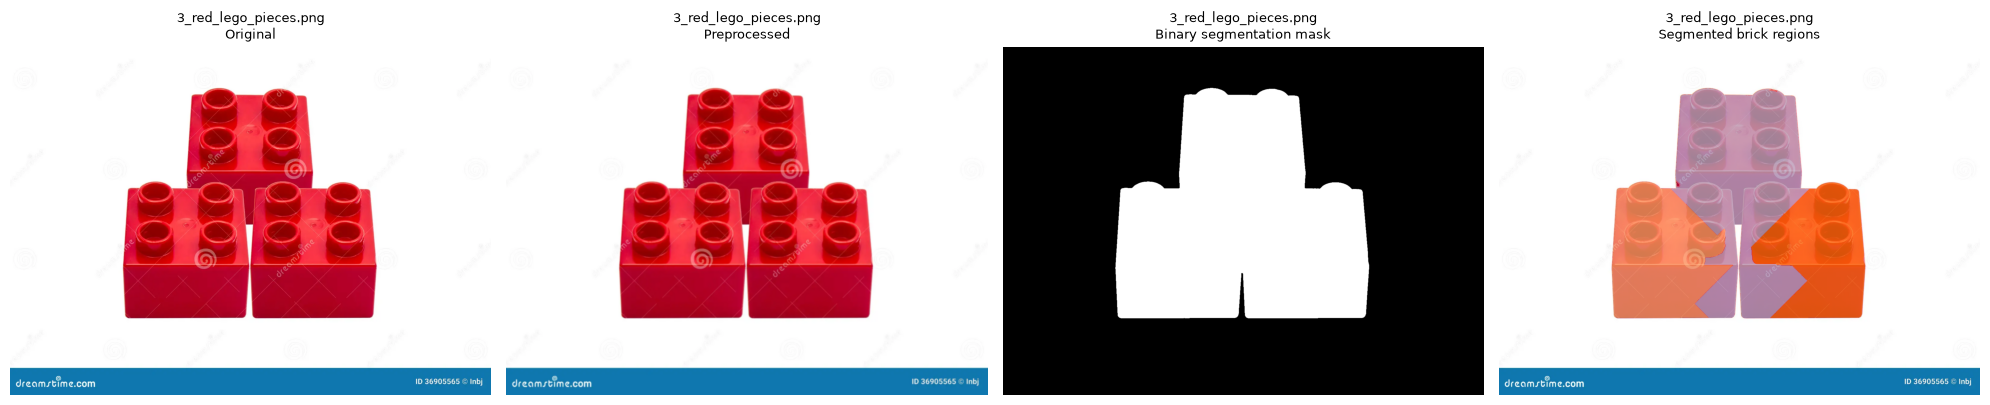

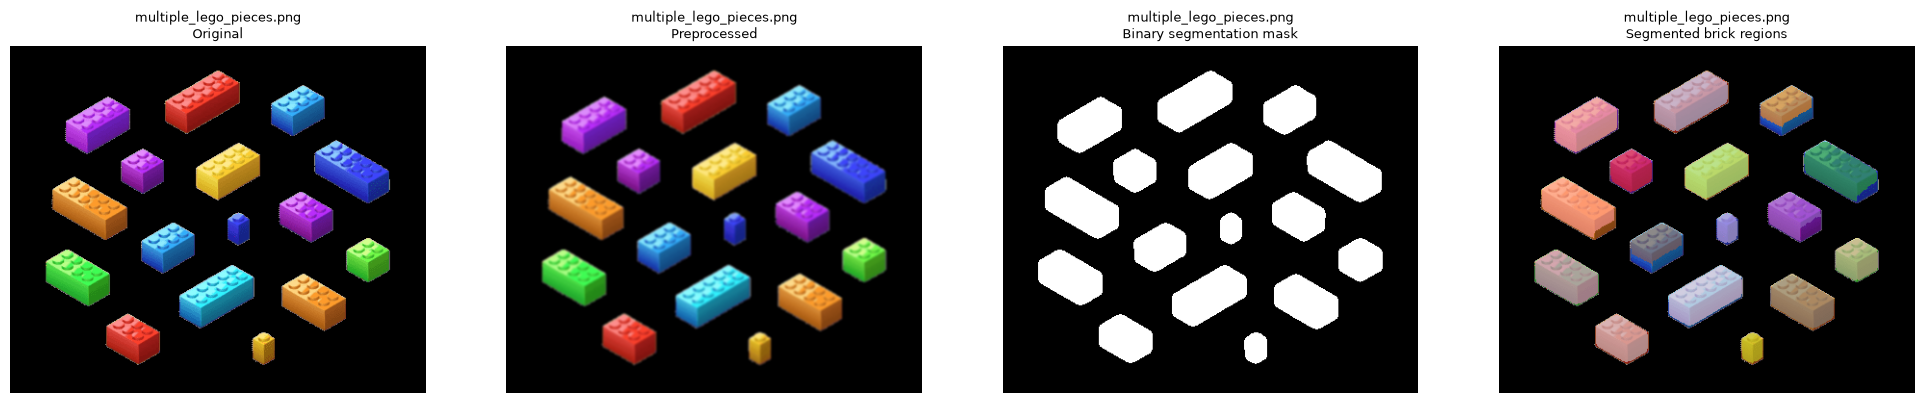

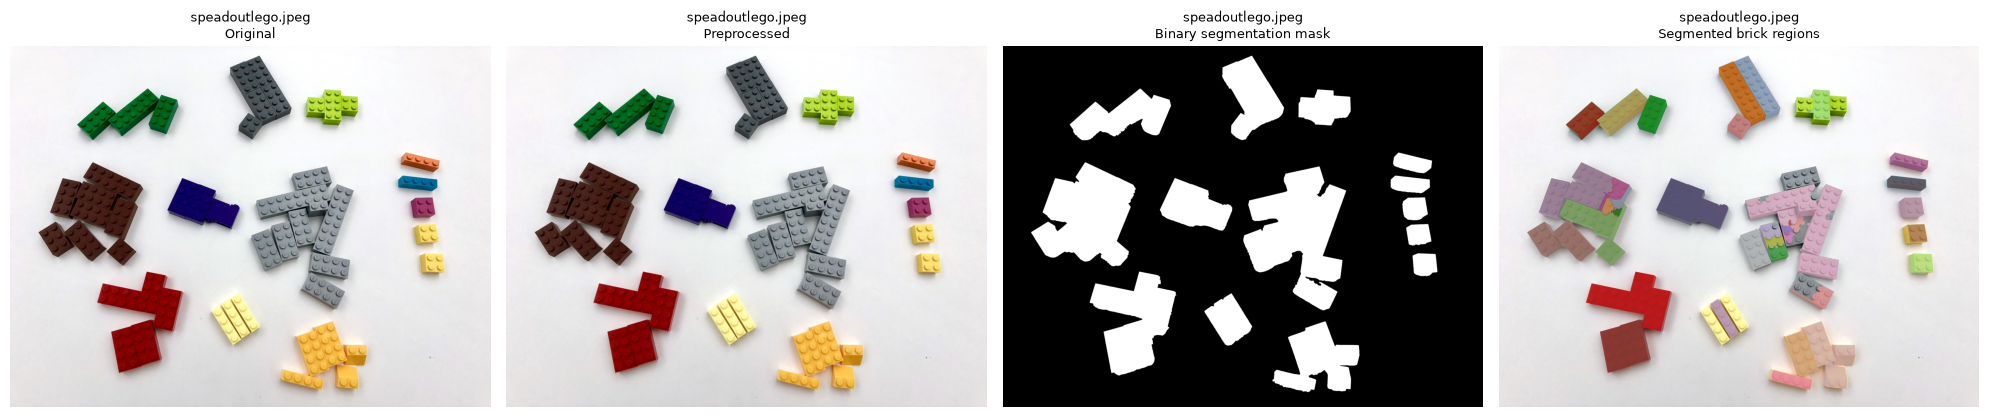

In [103]:
all_results = {}
for path in image_files:
    # --- Segment the photo ---
    photo = cv2.imread(str(path), cv2.IMREAD_COLOR)
    result = segment_lego_image(photo)
    all_results[path.name] = (photo, result)

    # --- Show the four Person 1 outputs side by side ---
    fig, axes = plt.subplots(1, 4, figsize=(20, 4))
    panels = [(photo, "Original"),
              (result["preprocessed"], "Preprocessed"),
              (result["mask"], "Binary segmentation mask"),
              (colour_labels(photo, result["labels"]), "Segmented brick regions")]
    for ax, (image, title) in zip(axes, panels):
        if image.ndim == 3:
            ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
        else:
            ax.imshow(image, cmap="gray")
        ax.set_title(f"{path.name}\n{title}", fontsize=9)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

## 11. Save the segmentation outputs (hand-off to Person 2)

Detection, bounding boxes, area filtering and counting are Person 2's stage, so Person 1 only saves the segmentation. For each photo, into `segmentation_output/`:

- `<name>_mask.png` – the binary foreground mask (bricks = 255).
- `<name>_labels.png` – the label image as **16-bit** PNG (0 = background, 1..N = brick regions). 16-bit is needed because 8-bit can only hold 255 labels. Read it with `cv2.imread(path, cv2.IMREAD_UNCHANGED)`.
- `<name>_segmented.png` – a coloured picture of the regions, for reports.

Inside the notebook, the next stages can also call `segment_lego_image(image)` and use `result["mask"]`, `result["labels"]` or `result["brick_masks"]`.

In [104]:
OUTPUT_DIR = Path("segmentation_output")
OUTPUT_DIR.mkdir(exist_ok=True)

# --- Save mask, label image and coloured result for every photo ---
for name, (photo, result) in all_results.items():
    stem = Path(name).stem
    cv2.imwrite(str(OUTPUT_DIR / f"{stem}_mask.png"), result["mask"])
    cv2.imwrite(str(OUTPUT_DIR / f"{stem}_labels.png"), result["labels"].astype(np.uint16))
    cv2.imwrite(str(OUTPUT_DIR / f"{stem}_segmented.png"), colour_labels(photo, result["labels"]))

print("Saved files:")
for saved_path in sorted(OUTPUT_DIR.iterdir()):
    print(" ", saved_path.name)

Saved files:
  2_red_lego_pieces_labels.png
  2_red_lego_pieces_mask.png
  2_red_lego_pieces_segmented.png
  3_red_lego_pieces_labels.png
  3_red_lego_pieces_mask.png
  3_red_lego_pieces_segmented.png
  giant_pile_labels.png
  giant_pile_mask.png
  giant_pile_segmented.png
  multiple_lego_pieces_labels.png
  multiple_lego_pieces_mask.png
  multiple_lego_pieces_segmented.png
  speadoutlego_labels.png
  speadoutlego_mask.png
  speadoutlego_segmented.png
